# Docling - DocLayNet layout pipeline

In [1]:
from pathlib import Path
import os
import subprocess
import sys
import time

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "methods").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "methods").is_dir():
    raise FileNotFoundError("Không tìm thấy thư mục gốc repository; hãy mở notebook từ project DO-AN-261.")

METHOD = "docling"
# Các split DocLayNet cần chạy: (dataset, split). Xem datasets/README.md.
RUNS = [
    ("doclaynet_test", "test"),         # ~4999 ảnh (test split)
]
IOU_THRESHOLD = 0.5
LIMIT = 0  # 0: toàn bộ ảnh trong tập dữ liệu; hoặc giới hạn số ảnh mỗi split (vd: 20)
FORCE_INFERENCE = False  # True: chạy lại inference và ghi đè; False: chỉ chạy ảnh chưa có prediction định dạng mới
FIGURE_LIMIT = 20
PROGRESS_EVERY = 1000  # in tiến độ inference mỗi N ảnh để notebook không quá dài


def predictions_dir(dataset):
    return ROOT / "outputs" / "predictions" / METHOD / dataset


def figures_dir(dataset):
    return ROOT / "outputs" / "reports" / f"{METHOD}_{dataset}"


try:
    import torch
    device = f"cuda ({torch.cuda.get_device_name()})" if torch.cuda.is_available() else "cpu"
except ImportError:
    device = "cpu"

print(f"Project: {ROOT}")
print(f"Method: {METHOD} | IoU >= {IOU_THRESHOLD} | device: {device}")
print(f"Inference: {'force rerun' if FORCE_INFERENCE else 'skip existing predictions'}")
for dataset, split in RUNS:
    print(f"  {dataset}/{split}: predictions -> {predictions_dir(dataset)}")


def is_progress_line(line):
    """Dòng tiến độ của run_inference.py: '  [12/4999] 12.png: ...' -> (12, 4999), ngược lại None."""
    text = line.strip()
    if not text.startswith("[") or "]" not in text:
        return None
    head = text[1:text.index("]")]
    if "/" not in head:
        return None
    done, total = head.split("/", 1)
    return (int(done), int(total)) if done.isdigit() and total.isdigit() else None


def run_script(command, progress_every=None):
    """Chạy script con, in log trực tiếp ra notebook; nếu script lỗi thì log lỗi gốc nằm ngay phía trên."""
    command = [str(part) for part in command]
    print("Running:", " ".join(command), flush=True)
    env = {**os.environ, "PYTHONUNBUFFERED": "1", "PYTHONIOENCODING": "utf-8"}
    process = subprocess.Popen(
        command, cwd=ROOT, env=env, text=True, encoding="utf-8", errors="replace",
        stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
    )
    for line in process.stdout:
        if "Loading weights" in line:
            continue
        progress = is_progress_line(line)
        if progress and progress_every and "FAILED" not in line:
            done, total = progress
            if done % progress_every and done != total:
                continue
        print(line, end="", flush=True)
    if process.wait() != 0:
        raise RuntimeError(f"{Path(command[1]).name} thất bại (exit code {process.returncode}), xem log phía trên.")

Project: D:\DLA\DO-AN-261
Method: docling | IoU >= 0.5 | device: cuda (NVIDIA GeForce RTX 4060 Laptop GPU)
Inference: skip existing predictions
  doclaynet_test/test: predictions -> D:\DLA\DO-AN-261\outputs\predictions\docling\doclaynet_test


## 1. Prediction

Chạy Docling trên từng split trong `RUNS` (tự dùng GPU nếu PyTorch có CUDA). Ảnh đã có prediction được bỏ qua; đặt `FORCE_INFERENCE = True` để chạy lại toàn bộ.

In [2]:
inference_script = ROOT / "methods" / METHOD / "src" / "run_inference.py"
MAX_ATTEMPTS = 200

# Docling/torch đôi khi crash ở tầng native (segfault) sau ~1000 ảnh liên tục.
# --skip-existing giúp lần chạy sau tiếp tục từ ảnh còn thiếu, nên tự chạy lại
# chừng nào lần trước còn tạo thêm được prediction (tránh lặp vô hạn khi lỗi cố định).
for dataset, split in RUNS:
    print(f"\n========== Inference: {dataset}/{split} ==========")
    out_dir = predictions_dir(dataset)
    command = [
        sys.executable, inference_script,
        "--dataset", dataset,
        "--limit", LIMIT,
        "--force" if FORCE_INFERENCE else "--skip-existing",
    ]
    for attempt in range(1, MAX_ATTEMPTS + 1):
        started = time.time()
        try:
            run_script(command, progress_every=PROGRESS_EVERY)
            break
        except RuntimeError as exc:
            new_files = sum(1 for p in out_dir.glob("*.json") if p.stat().st_mtime >= started)
            if attempt == MAX_ATTEMPTS or new_files == 0:
                raise
            print(f"[notebook] Lần {attempt} dừng sau {new_files} ảnh mới ({exc}). Chạy tiếp các ảnh còn thiếu...")
            command[-1] = "--skip-existing"
    print(f"Predictions: {out_dir}")


========== Inference: doclaynet_test/test ==========
Running: D:\DLA\docling_env\Scripts\python.exe D:\DLA\DO-AN-261\methods\docling\src\run_inference.py --dataset doclaynet_test --limit 0 --skip-existing


[docling] 0 image(s) to predict from D:\DLA\DO-AN-261\datasets\doclaynet_test\processed\images (existing predictions skipped)


[docling] No work to do. Predictions are in D:\DLA\DO-AN-261\outputs\predictions\docling\doclaynet_test


Predictions: D:\DLA\DO-AN-261\outputs\predictions\docling\doclaynet_test


## 2. Metrics and Evaluation Chart

Đánh giá từng split trong `RUNS` (`outputs/predictions/docling/<dataset>/`).
- **Strict**: Yêu cầu khớp cả tọa độ (IoU >= threshold) và đúng nhãn.
- **Loose**: Chỉ đánh giá khả năng định vị (localization), bỏ qua nhãn.
- **COCO mAP / AR**: mAP@[.5:.95], AP50, AP75, AR (cả theo kích thước) và AP theo từng class.
- **Runtime**: thời gian xử lý mỗi trang (mean/median/p95, không tính load model), peak RAM/VRAM.
- **Biểu đồ**: Trực quan hóa Precision, Recall, F1 theo từng class và so sánh Strict vs Loose.


========== Evaluation: doclaynet_test/test ==========
Running: D:\DLA\docling_env\Scripts\python.exe D:\DLA\DO-AN-261\scripts\evaluate_predictions.py --method docling --dataset doclaynet_test --split test --iou-threshold 0.5 --loose --plot D:\DLA\DO-AN-261\outputs\reports\docling_doclaynet_test\metrics_chart.png


Evaluation: docling on doclaynet_test/test | 4999 images | GT=66,531 boxes | Predictions=67,549 boxes | IoU >= 0.5


=== Strict (location and class) ===


Micro: Precision=0.851  Recall=0.864  F1=0.858  TP=57510 FP=10039 FN=9021  mean IoU=0.908


Macro (mean across 11 ground-truth classes): Precision=0.776  Recall=0.785  F1=0.780


...

Title                 0.000    0.000


=== Runtime ===


Time/page (4999 pages): mean=0.162s  median=0.121s  p95=0.339s


Peak RAM=8,975 MB  Peak VRAM=298 MB  model load=4.0s  device=cuda:NVIDIA GeForce RTX 4060 Laptop GPU  (3 run(s))


Evaluation Chart (D:\DLA\DO-AN-261\outputs\reports\docling_doclaynet_test\metrics_chart.png):


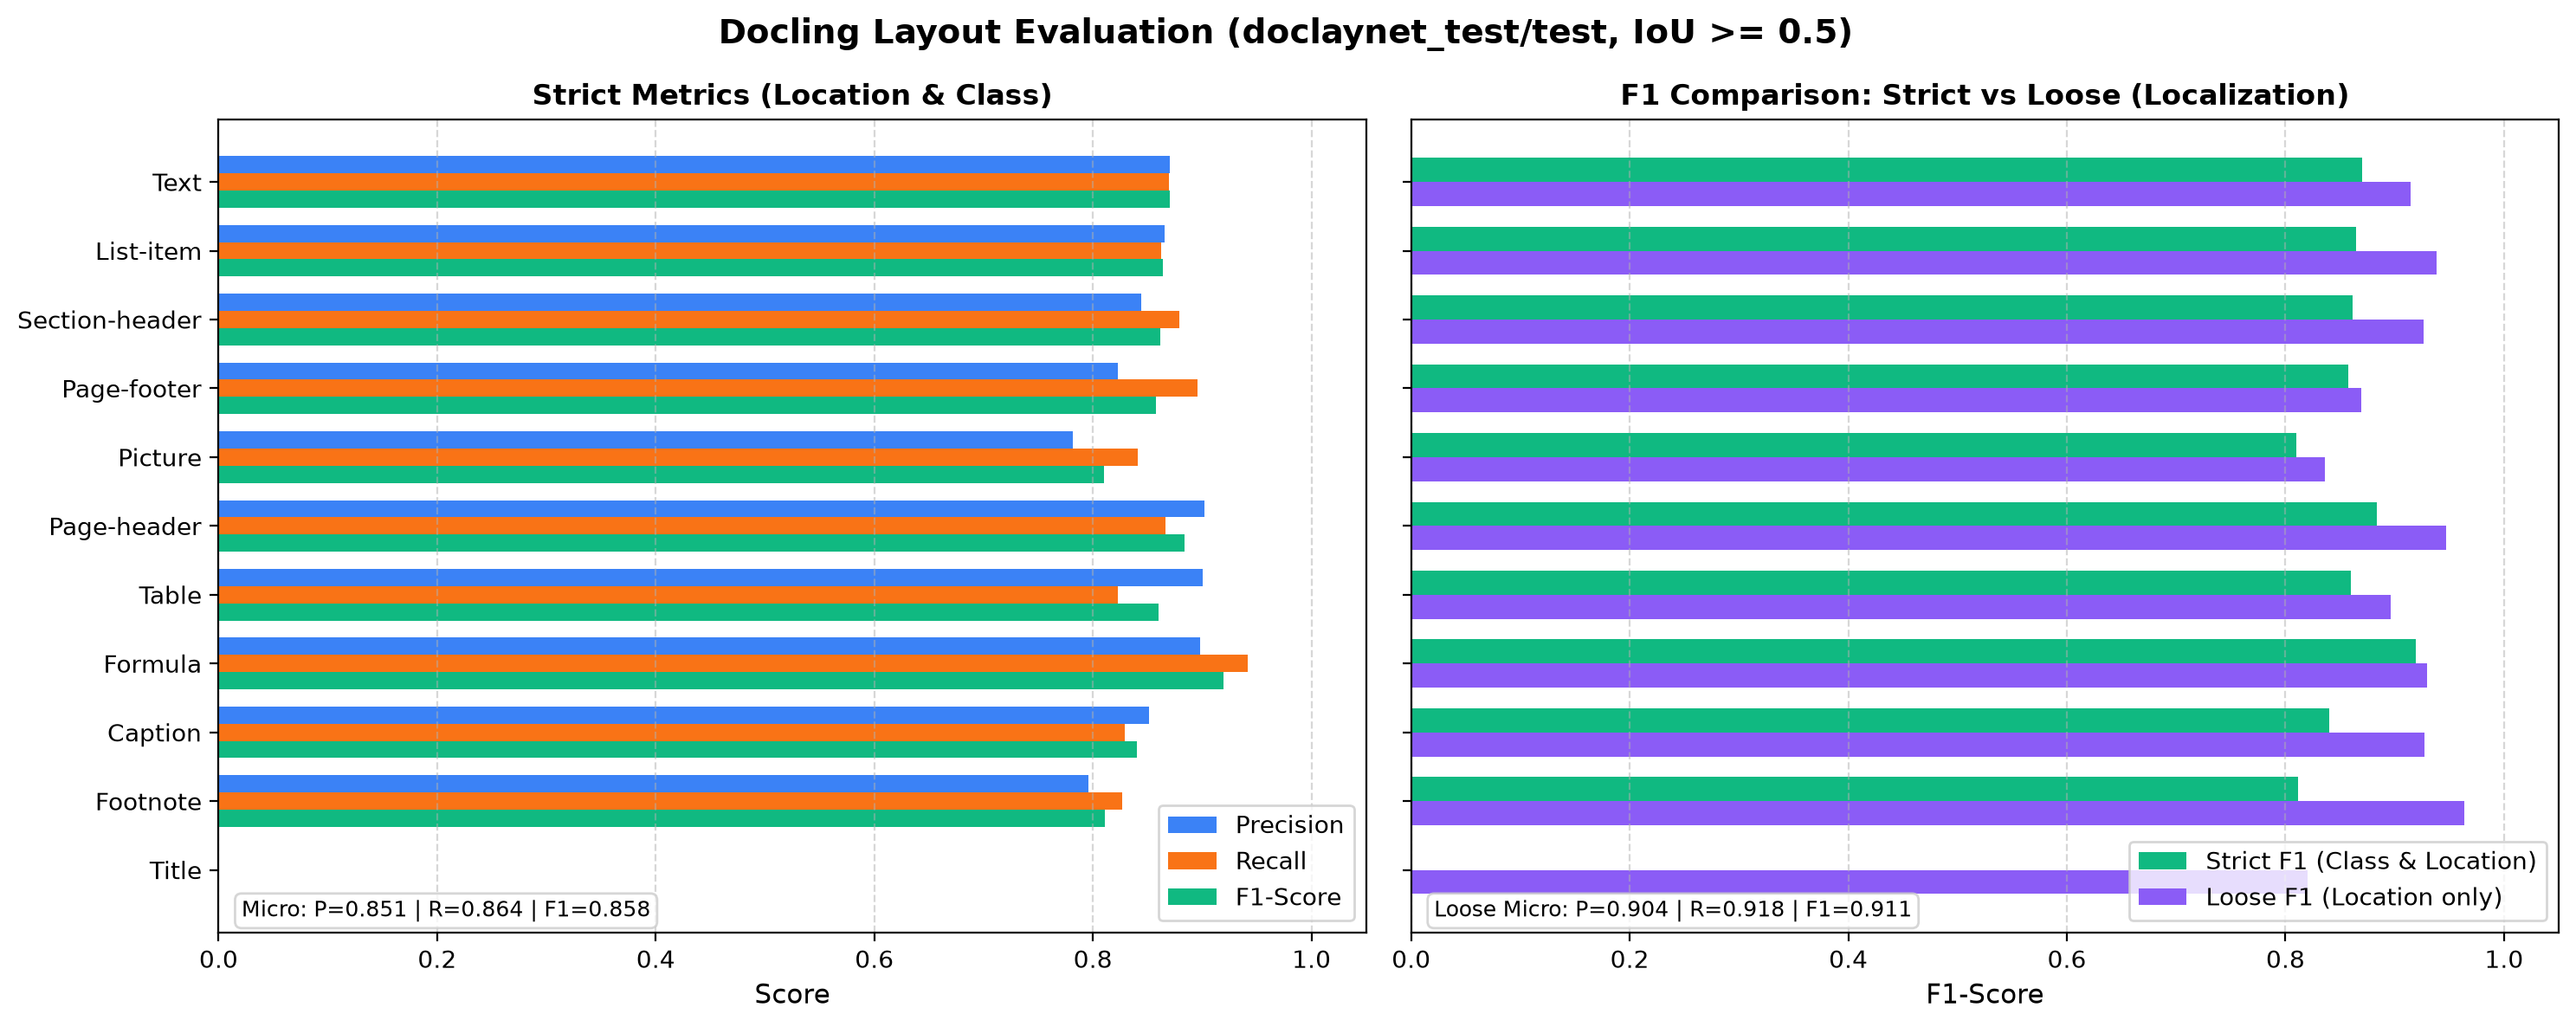

In [3]:
from IPython.display import Image as DisplayImage, display

evaluation_script = ROOT / "scripts" / "evaluate_predictions.py"
for dataset, split in RUNS:
    print(f"\n========== Evaluation: {dataset}/{split} ==========")
    chart_file = figures_dir(dataset) / "metrics_chart.png"
    command = [
        sys.executable, evaluation_script,
        "--method", METHOD,
        "--dataset", dataset,
        "--split", split,
        "--iou-threshold", IOU_THRESHOLD,
        "--loose",
        "--plot", chart_file,
    ]
    if LIMIT > 0:
        command.append("--allow-incomplete")  # chỉ đánh giá trên các ảnh đã có prediction
    run_script(command)

    if chart_file.is_file():
        print(f"Evaluation Chart ({chart_file}):")
        display(DisplayImage(filename=str(chart_file)))

## 3. Ground Truth vs. Prediction Examples

Trực quan hóa đối chiếu ảnh Ground Truth và kết quả dự đoán của Docling cho `FIGURE_LIMIT` ảnh đầu mỗi split. Ảnh kết quả được lưu tại `outputs/reports/docling_<dataset>/`.


========== Visualization: doclaynet_test/test ==========
Running: D:\DLA\docling_env\Scripts\python.exe D:\DLA\DO-AN-261\visualization\scripts\visualize_predictions.py --method docling --dataset doclaynet_test --split test --limit 20 --output-dir D:\DLA\DO-AN-261\outputs\reports\docling_doclaynet_test


[viz] Ve 20 anh (docling vs ground truth) tu D:\DLA\DO-AN-261\visualization\scripts\..\..\outputs\predictions\docling\doclaynet_test


  [ok] 1.png


  [ok] 2.png


  [ok] 3.png


...

  [ok] 19.png


  [ok] 20.png


  [ok] 21.png


[viz] Xong. Anh luu tai D:\DLA\DO-AN-261\outputs\reports\docling_doclaynet_test


Ví dụ ảnh đối chiếu: D:\DLA\DO-AN-261\outputs\reports\docling_doclaynet_test\1.png


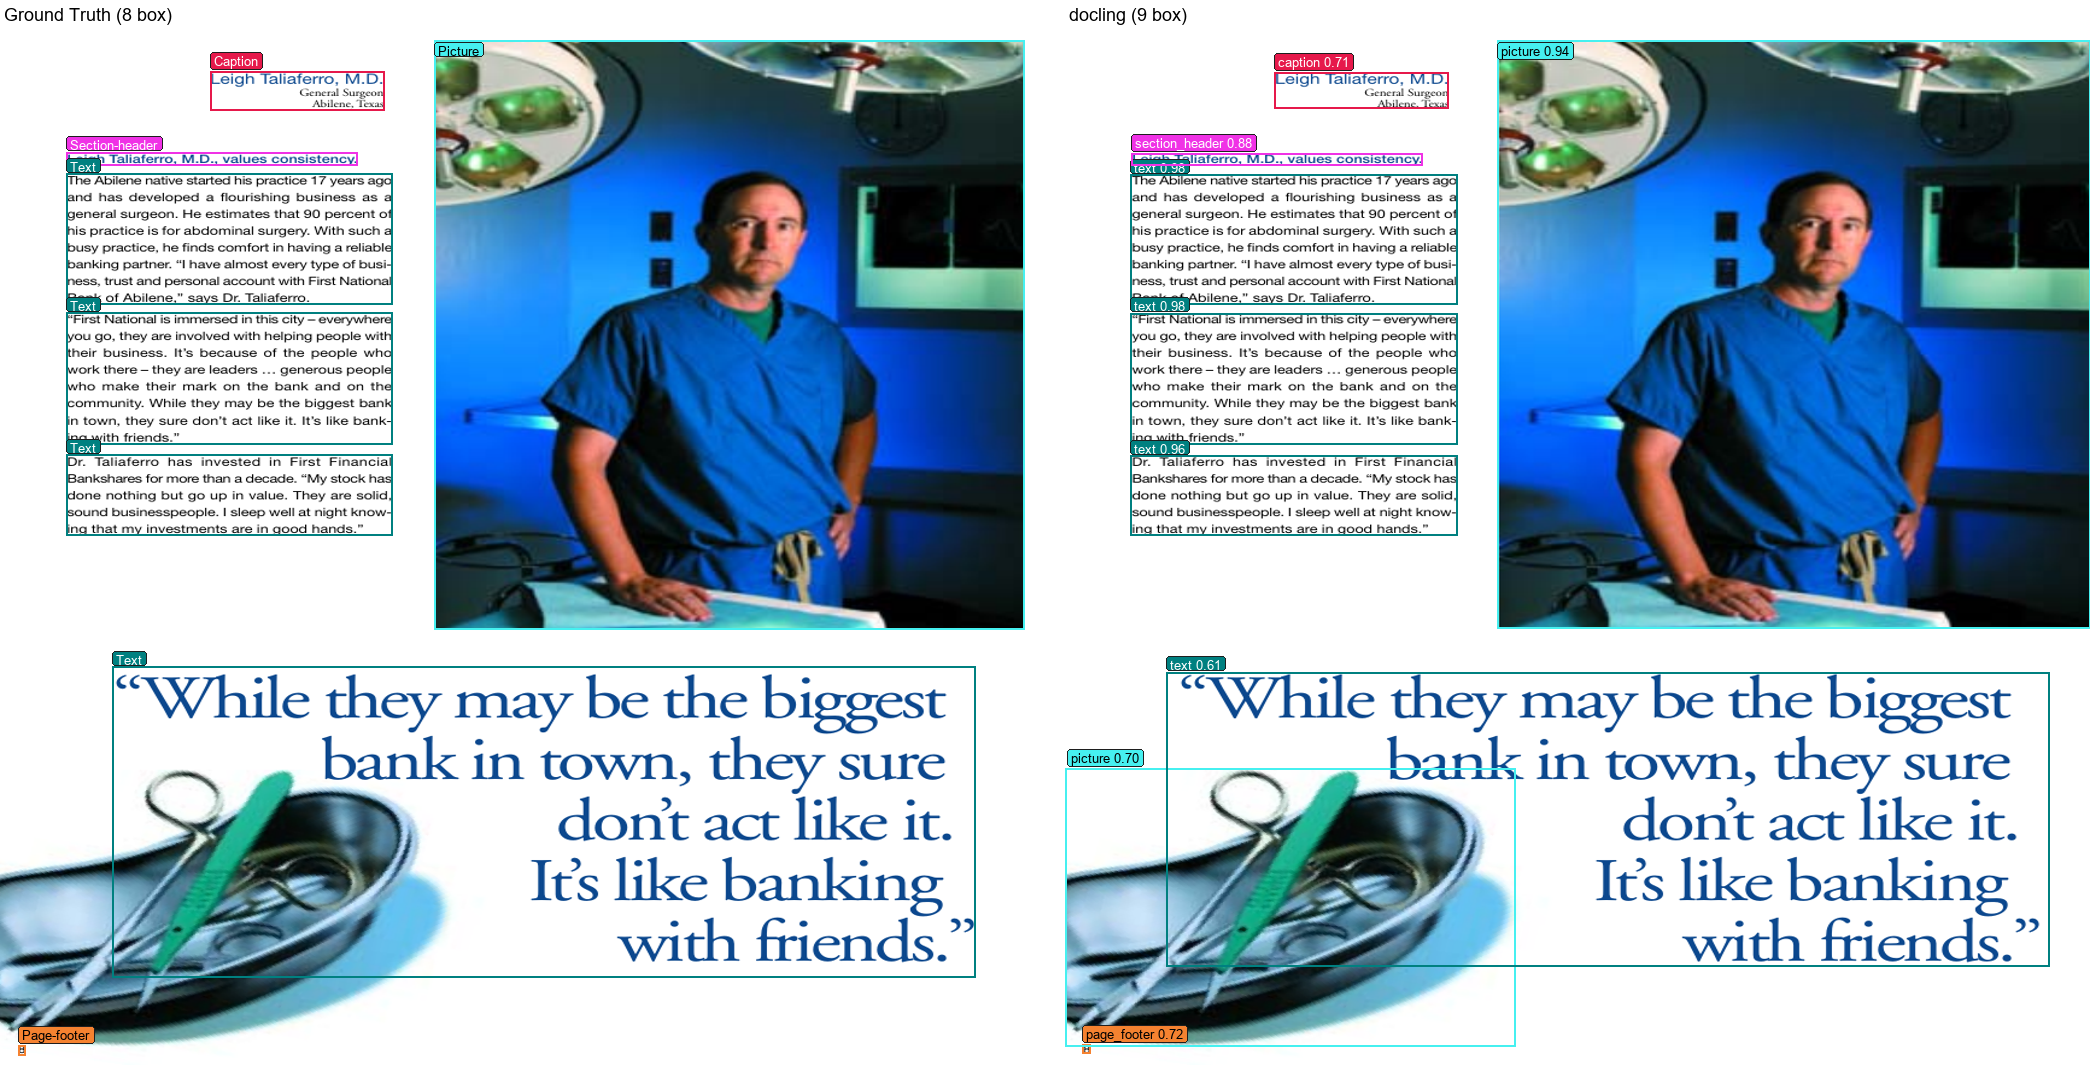

In [4]:
from IPython.display import Image as DisplayImage, display

visualizer = ROOT / "visualization" / "scripts" / "visualize_predictions.py"
for dataset, split in RUNS:
    print(f"\n========== Visualization: {dataset}/{split} ==========")
    out_dir = figures_dir(dataset)
    run_script([
        sys.executable, visualizer,
        "--method", METHOD,
        "--dataset", dataset,
        "--split", split,
        "--limit", FIGURE_LIMIT,
        "--output-dir", out_dir,
    ])

    figure_files = sorted(
        (p for p in out_dir.glob("*.png") if p.stem.isdigit()),
        key=lambda p: int(p.stem),
    )
    if figure_files:
        print(f"Ví dụ ảnh đối chiếu: {figure_files[0]}")
        display(DisplayImage(filename=str(figure_files[0])))
    else:
        print(f"Không có hình ảnh nào trong {out_dir}")

## Files đầu ra và báo cáo

- Predictions JSON: `outputs/predictions/docling/<dataset>/<image_id>.json`
- Runtime (thời gian/trang, peak RAM/VRAM): `outputs/runtime/docling/<dataset>.json`
- Biểu đồ metric + ảnh đối chiếu: `outputs/reports/docling_<dataset>/`
- Ground Truth COCO: `datasets/<dataset>/processed/annotations/<split>.json`
  (`doclaynet` -> `train.json`, `doclaynet_val` -> `validation.json`, `doclaynet_test` -> `test.json`)